# Section 1: Environment Setup & Data Ingestion
This section handles library imports, directory validation, automated artifact unpacking, and alignment of the feature table with clinical metadata.

In [ ]:
import os
import io
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-quality plot aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

# Input files are stored in the repository's data/ directory.
from pathlib import Path
DATA_DIR = Path('data')

# 1. Verify Required Files
required_files = [
    'feature-table.tsv',
    'core_metadata_healthy_vs_precancer.tsv',
    'taxonomy.qza',
    'ancombc2-significant-taxa.tsv',
    'ordination.txt',
    'shannon.tsv',
    'observed_features.tsv'
]

missing_files = [f for f in required_files if not (DATA_DIR / f).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing required input files: {missing_files}. Ensure files are in the data/ directory.")
print("All input files successfully detected.")

# 2. Extract QIIME 2 Taxonomy Artifact (Once)
if not (DATA_DIR / 'taxonomy.tsv').exists():
    with zipfile.ZipFile(DATA_DIR / 'taxonomy.qza') as z:
        member = [x for x in z.namelist() if x.endswith('data/taxonomy.tsv')][0]
        with open(DATA_DIR / 'taxonomy.tsv', 'wb') as f_out:
            f_out.write(z.read(member))
    print("Extracted: taxonomy.tsv")
else:
    print("Found existing: taxonomy.tsv")

# 3. Loading the data
ft = pd.read_csv(DATA_DIR / 'feature-table.tsv', sep='\t', skiprows=1, index_col=0)
md = pd.read_csv(DATA_DIR / 'core_metadata_healthy_vs_precancer.tsv', sep='\t', index_col=0)
tax = pd.read_csv(DATA_DIR / 'taxonomy.tsv', sep='\t', index_col=0)
ancom_sig = pd.read_csv(DATA_DIR / 'ancombc2-significant-taxa.tsv', sep='\t')

# Transpose feature table to (samples x ASVs) and align strictly to metadata indices
X = ft.T.loc[md.index]
y = (md['disease-status'] == 'Precancer').astype(int)

print(f"Matrix Dimension: {X.shape[0]} samples x {X.shape[1]} raw ASVs")
print(f"Cohort Balance: {np.bincount(y)[0]} Healthy (0), {np.bincount(y)[1]} Precancer (1)")

All input files successfully detected.
Found existing: taxonomy.tsv
Matrix Dimension: 251 samples x 12932 raw ASVs
Cohort Balance: 127 Healthy (0), 124 Precancer (1)


# Section 2: Microbial Community Diversity & Taxonomic Profiling
This section analyzes microbial alpha diversity (Shannon entropy and Observed ASVs), beta diversity (Bray-Curtis PCoA with dynamic variance parsing and PERMANOVA test), and community taxonomic composition at the phylum and genus levels.

Alpha Diversity Significance Tests:
  - Shannon Diversity Mann-Whitney p-value: 0.2021
  - Observed ASVs Richness Mann-Whitney p-value: 0.7247


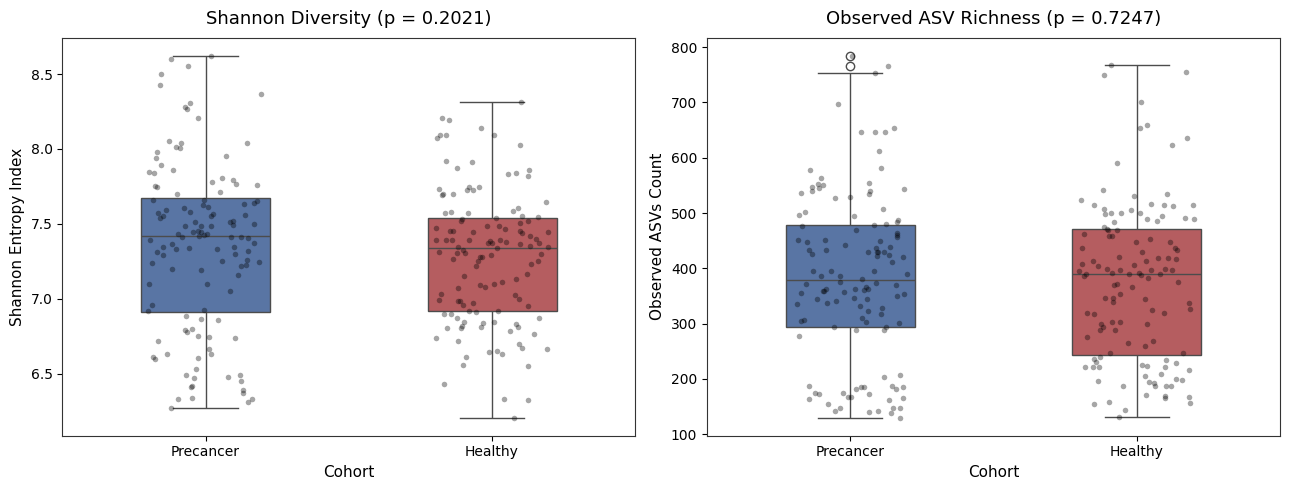


Beta Diversity Statistical Tests (Bray-Curtis):
  - PERMANOVA: Pseudo-F = 4.4918, R2 = 1.77%, p = 0.0010 (999 permutations)
  - PERMDISP:  F = 0.0010, p = 0.9740 (dispersion homogeneous between groups)
  - Sensitivity Check (Excluding left-hand PCoA cluster, PCoA1 < -0.2; N = 223):
    Pseudo-F = 4.3671, R2 = 1.94%, p = 0.0010


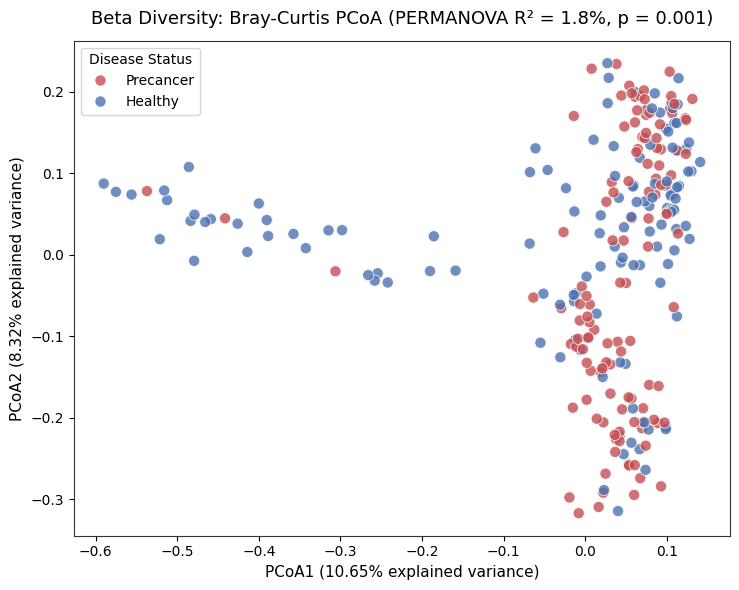

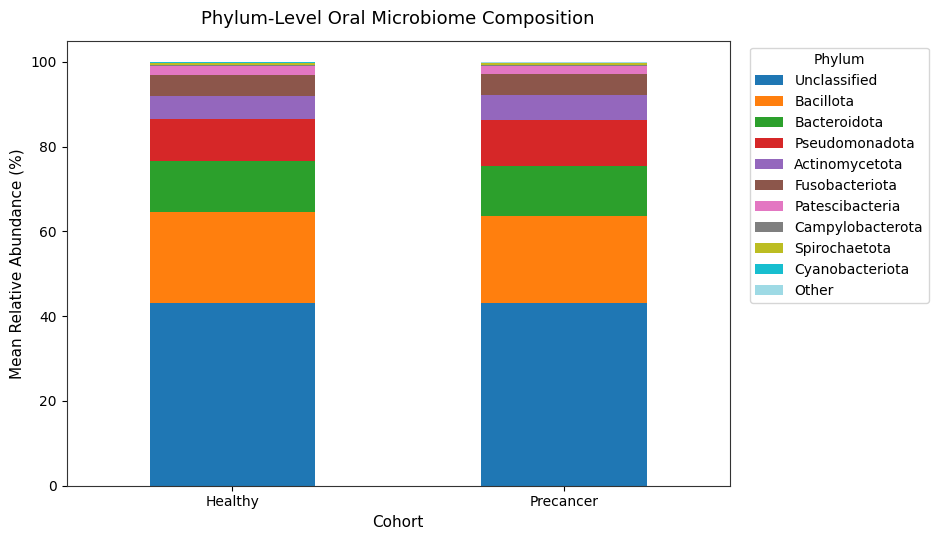

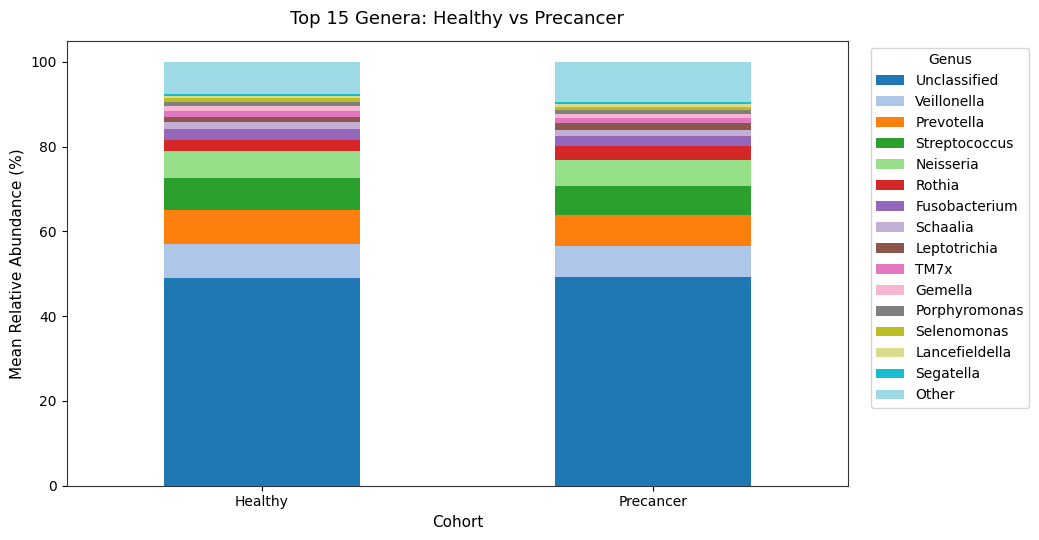

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, f_oneway
from scipy.spatial.distance import pdist, squareform

# 1. Alpha Diversity Analysis (Shannon & Observed ASVs)
shannon = pd.read_csv(DATA_DIR / "shannon.tsv", sep="\t", index_col=0)
observed = pd.read_csv(DATA_DIR / "observed_features.tsv", sep="\t", index_col=0)

shannon_df = shannon.copy()
shannon_df.columns = ["Shannon"]
shannon_df["Disease"] = md.loc[shannon_df.index, "disease-status"]

observed_df = observed.copy()
observed_df.columns = ["Observed_ASVs"]
observed_df["Disease"] = md.loc[observed_df.index, "disease-status"]

_, p_shannon = mannwhitneyu(
    shannon_df.loc[shannon_df["Disease"] == "Healthy", "Shannon"],
    shannon_df.loc[shannon_df["Disease"] == "Precancer", "Shannon"],
    alternative="two-sided"
)

_, p_observed = mannwhitneyu(
    observed_df.loc[observed_df["Disease"] == "Healthy", "Observed_ASVs"],
    observed_df.loc[observed_df["Disease"] == "Precancer", "Observed_ASVs"],
    alternative="two-sided"
)

print(f"Alpha Diversity Significance Tests:")
print(f"  - Shannon Diversity Mann-Whitney p-value: {p_shannon:.4f}")
print(f"  - Observed ASVs Richness Mann-Whitney p-value: {p_observed:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=shannon_df, x="Disease", y="Shannon", hue="Disease", palette=["#4C72B0", "#C44E52"], legend=False, ax=axes[0], width=0.45)
sns.stripplot(data=shannon_df, x="Disease", y="Shannon", color="black", alpha=0.35, size=4, jitter=0.2, ax=axes[0])
axes[0].set_title(f"Shannon Diversity (p = {p_shannon:.4f})", fontsize=13, pad=10)
axes[0].set_ylabel("Shannon Entropy Index", fontsize=11)
axes[0].set_xlabel("Cohort", fontsize=11)

sns.boxplot(data=observed_df, x="Disease", y="Observed_ASVs", hue="Disease", palette=["#4C72B0", "#C44E52"], legend=False, ax=axes[1], width=0.45)
sns.stripplot(data=observed_df, x="Disease", y="Observed_ASVs", color="black", alpha=0.35, size=4, jitter=0.2, ax=axes[1])
axes[1].set_title(f"Observed ASV Richness (p = {p_observed:.4f})", fontsize=13, pad=10)
axes[1].set_ylabel("Observed ASVs Count", fontsize=11)
axes[1].set_xlabel("Cohort", fontsize=11)
plt.tight_layout()
plt.show()

# 2. Beta Diversity Analysis (Dynamic PCoA, PERMANOVA & PERMDISP)
with open(DATA_DIR / "ordination.txt", encoding="utf-8") as f:
    lines = f.read().splitlines()

prop_line_idx = next(i for i, line in enumerate(lines) if line.startswith("Proportion explained\t"))
proportions = [float(val) for val in lines[prop_line_idx + 1].split("\t") if val.strip()]
pcoa1_pct = proportions[0] * 100
pcoa2_pct = proportions[1] * 100

site_start = next(i for i, line in enumerate(lines) if line.startswith("Site\t"))
site_end = next((i for i in range(site_start + 1, len(lines)) if lines[i] == "" or lines[i].startswith("Site constraints")), len(lines))
site_lines = lines[site_start + 1:site_end]

pcoa = pd.DataFrame(
    [line.split("\t")[:3] for line in site_lines if line.strip()],
    columns=["SampleID", "PCoA1", "PCoA2"]
)
pcoa["PCoA1"] = pd.to_numeric(pcoa["PCoA1"])
pcoa["PCoA2"] = pd.to_numeric(pcoa["PCoA2"])
pcoa["Disease"] = pcoa["SampleID"].map(md["disease-status"])

# Distance Matrix Calculation
common_samples = pd.Index(pcoa['SampleID']).intersection(X.index)
bc_dist = squareform(pdist(X.loc[common_samples].values, metric='braycurtis'))
groups = md.loc[common_samples, 'disease-status'].values

# PERMANOVA Function (Anderson 2001)
def run_permanova(dist_mat, labels, permutations=999, seed=42):
    np.random.seed(seed)
    N = len(labels)
    unique_groups, group_idx = np.unique(labels, return_inverse=True)
    k = len(unique_groups)
    d2 = dist_mat ** 2
    ss_total = np.sum(d2) / (2.0 * N)

    def calc_ss_within(grp_assignment):
        ss_w = 0.0
        for g in range(k):
            in_group = (grp_assignment == g)
            n_g = np.sum(in_group)
            if n_g > 1:
                sub_d2 = d2[np.ix_(in_group, in_group)]
                ss_w += np.sum(sub_d2) / (2.0 * n_g)
        return ss_w

    ss_within = calc_ss_within(group_idx)
    ss_between = ss_total - ss_within
    df_between = k - 1
    df_within = N - k
    f_stat = (ss_between / df_between) / (ss_within / df_within)
    r2 = ss_between / ss_total

    perm_f = []
    for _ in range(permutations):
        perm_assignment = np.random.permutation(group_idx)
        perm_ss_w = calc_ss_within(perm_assignment)
        perm_ss_b = ss_total - perm_ss_w
        perm_f.append((perm_ss_b / df_between) / (perm_ss_w / df_within))

    p_val = (np.sum(np.array(perm_f) >= f_stat) + 1.0) / (permutations + 1.0)
    return f_stat, r2, p_val

# PERMDISP Function (Multivariate Homogeneity of Groups Dispersions)
def run_permdisp(dist_mat, labels, permutations=999, seed=42):
    np.random.seed(seed)
    N = len(labels)
    H = np.eye(N) - np.ones((N, N)) / N
    d2 = dist_mat ** 2
    G = -0.5 * H.dot(d2).dot(H)
    eigvals, eigvecs = np.linalg.eigh(G)
    idx = np.argsort(eigvals)[::-1]
    eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]
    pos = eigvals > 1e-10
    coords = eigvecs[:, pos] * np.sqrt(eigvals[pos])

    unique_groups = np.unique(labels)
    dists = np.zeros(N)
    for g in unique_groups:
        m = (labels == g)
        centroid = coords[m].mean(axis=0)
        dists[m] = np.sqrt(np.sum((coords[m] - centroid)**2, axis=1))

    group_dists = [dists[labels == g] for g in unique_groups]
    f_stat, _ = f_oneway(*group_dists)

    perm_f = []
    for _ in range(permutations):
        p_labels = np.random.permutation(labels)
        p_dists = [dists[p_labels == g] for g in unique_groups]
        pf, _ = f_oneway(*p_dists)
        perm_f.append(pf)
    p_val = (np.sum(np.array(perm_f) >= f_stat) + 1.0) / (permutations + 1.0)
    return f_stat, p_val

f_stat, r2, p_val = run_permanova(bc_dist, groups, permutations=999)
f_disp, p_disp = run_permdisp(bc_dist, groups, permutations=999)

print(f"\nBeta Diversity Statistical Tests (Bray-Curtis):")
print(f"  - PERMANOVA: Pseudo-F = {f_stat:.4f}, R2 = {r2*100:.2f}%, p = {p_val:.4f} (999 permutations)")
disp_note = "dispersion homogeneous between groups" if p_disp > 0.05 else "dispersion differs between groups"
print(f"  - PERMDISP:  F = {f_disp:.4f}, p = {p_disp:.4f} ({disp_note})")

# Sensitivity Check: Exclude left outlier cluster (PCoA1 < -0.2)
no_left_idx = pcoa[pcoa['PCoA1'] >= -0.2]['SampleID'].values
bc_dist_no_left = squareform(pdist(X.loc[no_left_idx].values, metric='braycurtis'))
groups_no_left = md.loc[no_left_idx, 'disease-status'].values
f_sub, r2_sub, p_sub = run_permanova(bc_dist_no_left, groups_no_left, permutations=999)
print(f"  - Sensitivity Check (Excluding left-hand PCoA cluster, PCoA1 < -0.2; N = {len(no_left_idx)}):")
print(f"    Pseudo-F = {f_sub:.4f}, R2 = {r2_sub*100:.2f}%, p = {p_sub:.4f}")

plt.figure(figsize=(7.5, 6))
sns.scatterplot(
    data=pcoa, x="PCoA1", y="PCoA2", hue="Disease",
    palette={"Healthy": "#4C72B0", "Precancer": "#C44E52"}, s=65, alpha=0.8
)
plt.xlabel(f"PCoA1 ({pcoa1_pct:.2f}% explained variance)", fontsize=11)
plt.ylabel(f"PCoA2 ({pcoa2_pct:.2f}% explained variance)", fontsize=11)
plt.title(f"Beta Diversity: Bray-Curtis PCoA (PERMANOVA R² = {r2*100:.1f}%, p = {p_val:.3f})", fontsize=13, pad=12)
plt.legend(title="Disease Status", frameon=True)
plt.tight_layout()
plt.show()

# 3. Taxonomic Composition (Phylum & Genus Relative Abundance)
asv_abundance = ft.T
common_asvs = asv_abundance.columns.intersection(tax.index)
abundance = asv_abundance[common_asvs]
taxonomy = tax.loc[common_asvs].copy()

relative_abundance = abundance.div(abundance.sum(axis=1), axis=0) * 100

taxonomy["Phylum"] = taxonomy["Taxon"].str.extract(r"p__([^;]+)")[0].fillna("Unclassified")
taxonomy["Genus"] = taxonomy["Taxon"].str.extract(r"g__([^;]+)")[0].fillna("Unclassified")

# Robust case-insensitive cleaning of unresolved markers (including Incertae_Sedis)
unresolved_markers = ["", "nan", "none", "unassigned", "uncultured", "incertae_sedis"]
taxonomy["Phylum"] = taxonomy["Phylum"].apply(lambda x: "Unclassified" if str(x).lower().strip() in unresolved_markers else x)
taxonomy["Genus"] = taxonomy["Genus"].apply(lambda x: "Unclassified" if str(x).lower().strip() in unresolved_markers else x)

grouped = relative_abundance.copy()
grouped["Disease"] = md.loc[grouped.index, "disease-status"]

phylum_group = grouped.groupby("Disease").mean().T
phylum_group["Phylum"] = taxonomy.loc[phylum_group.index, "Phylum"]
phylum_group = phylum_group.groupby("Phylum").sum()

top_phyla = phylum_group.sum(axis=1).nlargest(10).index
phylum_plot = phylum_group.loc[top_phyla].copy()
phylum_plot.loc["Other"] = phylum_group.drop(index=top_phyla).sum()
phylum_plot = phylum_plot.T

genus_group = grouped.groupby("Disease").mean().T
genus_group["Genus"] = taxonomy.loc[genus_group.index, "Genus"]
genus_group = genus_group.groupby("Genus").sum()

top_genera = genus_group.sum(axis=1).nlargest(15).index
genus_plot = genus_group.loc[top_genera].copy()
genus_plot.loc["Other"] = genus_group.drop(index=top_genera).sum()
genus_plot = genus_plot.T

ax1 = phylum_plot.plot(kind="bar", stacked=True, figsize=(9.5, 5.5), colormap="tab20")
ax1.set_ylabel("Mean Relative Abundance (%)", fontsize=11)
ax1.set_xlabel("Cohort", fontsize=11)
ax1.set_title("Phylum-Level Oral Microbiome Composition", fontsize=13, pad=12)
ax1.legend(title="Phylum", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ax2 = genus_plot.plot(kind="bar", stacked=True, figsize=(10.5, 5.5), colormap="tab20")
ax2.set_ylabel("Mean Relative Abundance (%)", fontsize=11)
ax2.set_xlabel("Cohort", fontsize=11)
ax2.set_title("Top 15 Genera: Healthy vs Precancer", fontsize=13, pad=12)
ax2.legend(title="Genus", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Section 3: Machine Learning Classification Pipeline
This section performs stratified train/test partitioning, defines leakage-safe compositional transformers (Prevalence Filter & Centered Log-Ratio), benchmarks multiple classification algorithms via 10x repeated 5-fold cross-validation, and evaluates the final Elastic-Net regularized logistic regression model on the locked test set.

Dataset Split:
  - Training fold: 200 samples (Healthy: 101, Precancer: 99)
  - Locked test set: 51 samples (Healthy: 26, Precancer: 25)

--- 10-Repeated 5-Fold Cross-Validation Performance (Training Set) ---
Dummy           ROC-AUC = 0.507 +/- 0.082
ElasticNet_LR   ROC-AUC = 0.843 +/- 0.057
RandomForest    ROC-AUC = 0.815 +/- 0.055
DecisionTree    ROC-AUC = 0.713 +/- 0.076

--- Final Locked Test Set Performance (N = 51) ---
Accuracy:              0.7451 (74.51%)
Precision:             0.7143 (71.43%)
Recall (Sensitivity):  0.8000 (80.00%)
Specificity:           0.6923 (69.23%)
F1-Score:              0.7547
ROC-AUC Score:         0.8385 (95% CI: [0.7084, 0.9348])


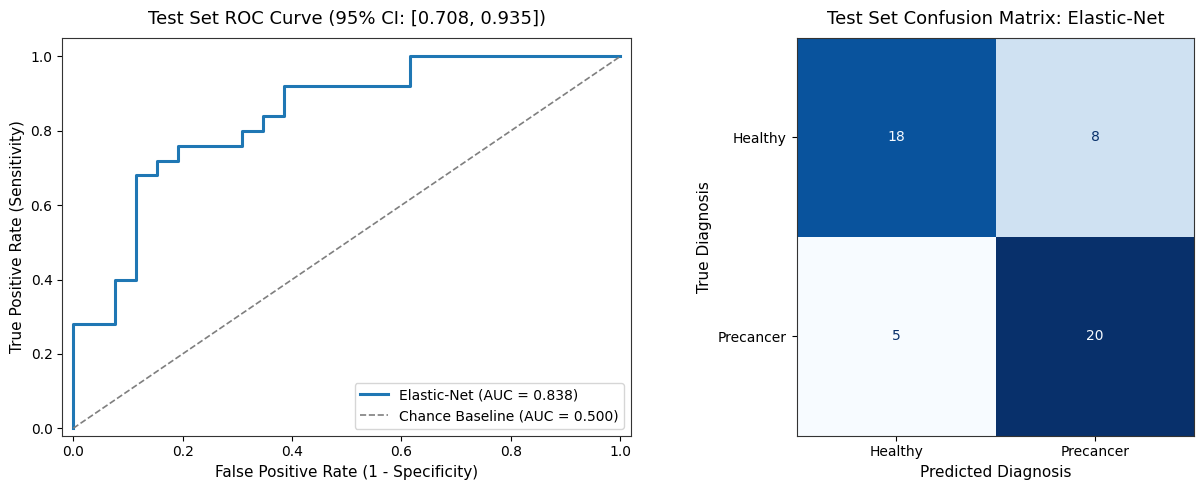

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

# 1. Test train split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#printing the split dimensions(train & test) with class
print("Dataset Split:")
print(f"  - Training fold: {X_train.shape[0]} samples (Healthy: {(y_train == 0).sum()}, Precancer: {(y_train == 1).sum()})")
print(f"  - Locked test set: {X_test.shape[0]} samples (Healthy: {(y_test == 0).sum()}, Precancer: {(y_test == 1).sum()})")

#converted the sample ids(index) to series and saved to csv
X_train.index.to_series().to_csv('train_sample_ids.csv', index=False)
X_test.index.to_series().to_csv('test_sample_ids.csv', index=False)

# 2. Compositional Feature Engineering Classes
class PrevalenceFilter(BaseEstimator, TransformerMixin):
    def __init__(self, min_prev=0.10):
        self.min_prev = min_prev

    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        self.keep_ = (X_arr > 0).mean(axis=0) >= self.min_prev
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.keep_]


class CLR(BaseEstimator, TransformerMixin):
    def __init__(self, pseudocount=0.5):
        self.pseudocount = pseudocount

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_arr = np.asarray(X, dtype=float)
        log_counts = np.log(X_arr + self.pseudocount)
        return log_counts - log_counts.mean(axis=1, keepdims=True)

#4 ml algorithms selected and defined for comparision
models = {
    'Dummy': DummyClassifier(strategy='stratified', random_state=1),
    'ElasticNet_LR': LogisticRegression(penalty='elasticnet', solver='saga',
                                         l1_ratio=0.5, C=0.1, max_iter=2000, random_state=1),
    'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=1),
    'DecisionTree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=1),
}

#cv
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=1)

print("\n--- 10-Repeated 5-Fold Cross-Validation Performance (Training Set) ---")

#pipeline for training
for name, model in models.items():
    steps = [('filter', PrevalenceFilter(min_prev=0.10)), ('clr', CLR())]
    if name == 'ElasticNet_LR':
        steps.append(('scale', StandardScaler()))
    steps.append(('model', model))

    pipe = Pipeline(steps)
    scores = cross_val_score(pipe, X_train.values, y_train.values, cv=cv, scoring='roc_auc')
    print(f"{name:15s} ROC-AUC = {scores.mean():.3f} +/- {scores.std():.3f}")

#final pipeline
final_pipe = Pipeline([
    ('filter', PrevalenceFilter(min_prev=0.10)),
    ('clr', CLR()),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(penalty='elasticnet', solver='saga',
                                  l1_ratio=0.5, C=0.1, max_iter=2000, random_state=1))
])

final_pipe.fit(X_train.values, y_train.values)
y_pred = final_pipe.predict(X_test.values)
y_proba = final_pipe.predict_proba(X_test.values)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

test_acc = accuracy_score(y_test, y_pred)
test_prec = precision_score(y_test, y_pred)
test_rec = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_proba)
test_spec = tn / (tn + fp)

# 1,000 bootstrap resamples of the test set (simple resampling with replacement) for the AUC 95% CI
np.random.seed(42)
n_bootstraps = 1000
bootstrapped_scores = []
y_test_arr = y_test.values

for _ in range(n_bootstraps):
    indices = np.random.choice(len(y_test_arr), len(y_test_arr), replace=True)
    if len(np.unique(y_test_arr[indices])) < 2:
        continue
    bootstrapped_scores.append(roc_auc_score(y_test_arr[indices], y_proba[indices]))

ci_lower = np.percentile(bootstrapped_scores, 2.5)
ci_upper = np.percentile(bootstrapped_scores, 97.5)

print("\n--- Final Locked Test Set Performance (N = 51) ---")
print(f"Accuracy:              {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Precision:             {test_prec:.4f} ({test_prec*100:.2f}%)")
print(f"Recall (Sensitivity):  {test_rec:.4f} ({test_rec*100:.2f}%)")
print(f"Specificity:           {test_spec:.4f} ({test_spec*100:.2f}%)")
print(f"F1-Score:              {test_f1:.4f}")
print(f"ROC-AUC Score:         {test_auc:.4f} (95% CI: [{ci_lower:.4f}, {ci_upper:.4f}])")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, color='#1F77B4', lw=2.2, label=f"Elastic-Net (AUC = {test_auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#7F7F7F", lw=1.2, label="Chance Baseline (AUC = 0.500)")
axes[0].set_xlim([-0.02, 1.02])
axes[0].set_ylim([-0.02, 1.05])
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
axes[0].set_title(f"Test Set ROC Curve (95% CI: [{ci_lower:.3f}, {ci_upper:.3f}])", fontsize=13, pad=10)
axes[0].legend(loc="lower right", frameon=True)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Healthy", "Precancer"])
disp.plot(ax=axes[1], values_format="d", cmap="Blues", colorbar=False)
axes[1].set_title("Test Set Confusion Matrix: Elastic-Net", fontsize=13, pad=10)
axes[1].set_xlabel("Predicted Diagnosis", fontsize=11)
axes[1].set_ylabel("True Diagnosis", fontsize=11)
plt.tight_layout()
plt.show()

# Section 4: Dual-Validation Biomarker Discovery & Taxonomy Parsing
This section isolates predictive non-zero feature coefficients from the Elastic-Net model, performs an intersection with statistically significant differentially abundant taxa from ANCOM-BC2 (q < 0.05), enforces directional concordance, and parses full taxonomic lineages with rank-aware fallbacks.



In [ ]:
import numpy as np
import pandas as pd

# 1. Extract Non-Zero Elastic-Net Coefficients
keep_mask = final_pipe.named_steps['filter'].keep_
kept_asv_ids = X_train.columns[keep_mask]
model_coefficients = final_pipe.named_steps['model'].coef_[0]

coef_df = pd.DataFrame({'ASV_ID': kept_asv_ids, 'coefficient': model_coefficients})
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False)
nonzero_features = coef_df[coef_df['coefficient'] != 0].copy()

# 2. Intersect with ANCOM-BC2
overlap = nonzero_features.merge(ancom_sig, left_on='ASV_ID', right_on='Feature ID', how='inner')

# 3. Directional Concordance Verification
overlap['Direction_Concordance'] = np.where(
    ((overlap['coefficient'] > 0) & (overlap['Direction'] == 'Enriched in Precancer'))
    | ((overlap['coefficient'] < 0) & (overlap['Direction'] == 'Depleted in Precancer')),
    'Concordant', 'Discordant'
)

candidates = overlap[overlap['Direction_Concordance'] == 'Concordant'].copy()

# 4. Taxonomy Resolution with Rank-Aware Fallback
def parse_best_taxonomy(taxon_str):
    parts = [x.strip() for x in str(taxon_str).split(";") if x.strip()]
    if not parts or parts[0].lower() in ['unassigned', 'nan', 'none']:
        return "Unassigned", "Unassigned"

    rank_map = {
        'd__': 'Domain', 'p__': 'Phylum', 'c__': 'Class',
        'o__': 'Order', 'f__': 'Family', 'g__': 'Genus', 's__': 'Species'
    }

    genus = "Unresolved"
    for p in parts:
        if p.startswith('g__'):
            val = p.replace('g__', '').strip()
            if val and val.lower() not in ['unassigned', 'uncultured', 'incertae_sedis', '']:
                genus = val

    deepest_label = "Unassigned"
    for p in reversed(parts):
        prefix = p[:3]
        val = p[3:].strip()
        if prefix in rank_map and val and val.lower() not in ['unassigned', 'uncultured', 'incertae_sedis', '']:
            deepest_label = f"{val} ({rank_map[prefix]})"
            break
        elif prefix == 'd__' and val:
            deepest_label = f"{val} (Domain)"
            break

    return genus, deepest_label

parsed_taxa = candidates['Taxon'].apply(parse_best_taxonomy)
candidates['Genus'] = [p[0] for p in parsed_taxa]
candidates['Best_Taxon_Label'] = [p[1] for p in parsed_taxa]
candidate_asvs = candidates['ASV_ID'].tolist()

output_columns = ['ASV_ID', 'Best_Taxon_Label', 'Genus', 'coefficient', 'LFC', 'q_value', 'Direction', 'Direction_Concordance']
candidates[output_columns].to_csv('Final_Candidate_Biomarkers.csv', index=False)

print(f"Final Candidate Biomarkers: {len(candidates)} concordant ASVs isolated.")
print(f"  - Genus-resolved: {(candidates['Genus'] != 'Unresolved').sum()}")
print(f"  - Higher-rank resolved / Unassigned: {(candidates['Genus'] == 'Unresolved').sum()}")
print("Saved final biomarkers to: Final_Candidate_Biomarkers.csv")
display(candidates[output_columns].head(10))

Final Candidate Biomarkers: 39 concordant ASVs isolated.
  - Genus-resolved: 15
  - Higher-rank resolved / Unassigned: 24
Saved final biomarkers to: Final_Candidate_Biomarkers.csv


,ASV_ID,Best_Taxon_Label,Genus,coefficient,LFC,q_value,Direction,Direction_Concordance
0,1b550faf62bea18ba2c565e22063173e,Escherichia-Shigella (Genus),Escherichia-Shigella,0.340737,0.246716,2.102404e-02,Enriched in Precancer,Concordant
1,780aed87b2793b5d0bd36de87d83997c,Bacteria (Domain),Unresolved,-0.321393,-0.363496,8.697331e-04,Depleted in Precancer,Concordant
2,af6146463132a98e5b68d763cd4f59ee,Bacteria (Domain),Unresolved,-0.246266,-0.411646,2.928290e-03,Depleted in Precancer,Concordant
3,ab261f2eca81c57b2871460dbfeba755,Unassigned,Unassigned,0.203771,1.455530,9.872492e-16,Enriched in Precancer,Concordant
4,5b99f179e4402e9da69e94652a0941ef,Phascolarctobacterium (Genus),Phascolarctobacterium,0.193639,0.795130,4.900000e-09,Enriched in Precancer,Concordant
5,0c9832decfd5fbac8af08a2f88b70ccf,F0058 (Genus),F0058,0.190301,0.540418,4.926000e-07,Enriched in Precancer,Concordant
6,e3f1f9f7fb637310068ca0e305c86c69,Saccharimonadales (Order),Unresolved,-0.187984,-0.532888,2.248700e-06,Depleted in Precancer,Concordant
7,f93728144089fe40f390441f10eb760c,Bacteria (Domain),Unresolved,0.177698,0.705901,3.200000e-09,Enriched in Precancer,Concordant
9,6a426425522d036024faa0288def6cc0,Lachnospiraceae (Family),Unresolved,-0.147872,-0.401329,6.763670e-05,Depleted in Precancer,Concordant
10,def2b624376f3cd210c6d8ce552caf61,Bacteria (Domain),Unresolved,-0.143428,-0.287869,1.742530e-02,Depleted in Precancer,Concordant


# Section 5: Candidate Biomarker Visualizations
This section plots:
1. Top 20 predictive features selected by the Elastic-Net regularized model.
2. ANCOM-BC2 Log Fold Change (LFC) effect sizes for all 39 concordant candidate biomarkers.
3. Log-relative abundance heatmap of the 39 biomarkers across all Healthy and Precancer samples.

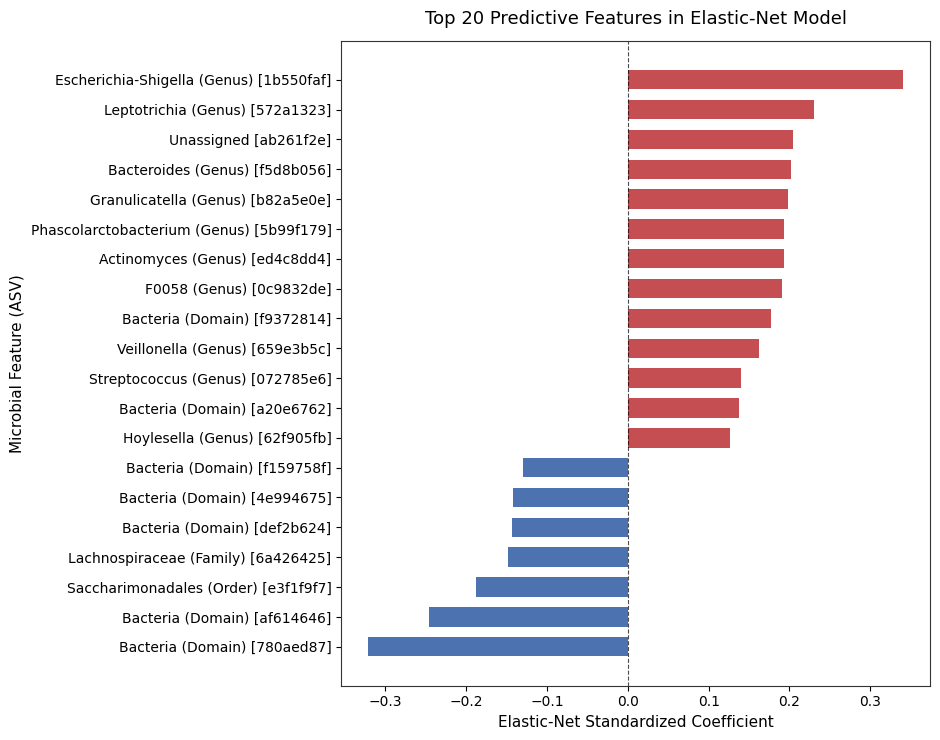

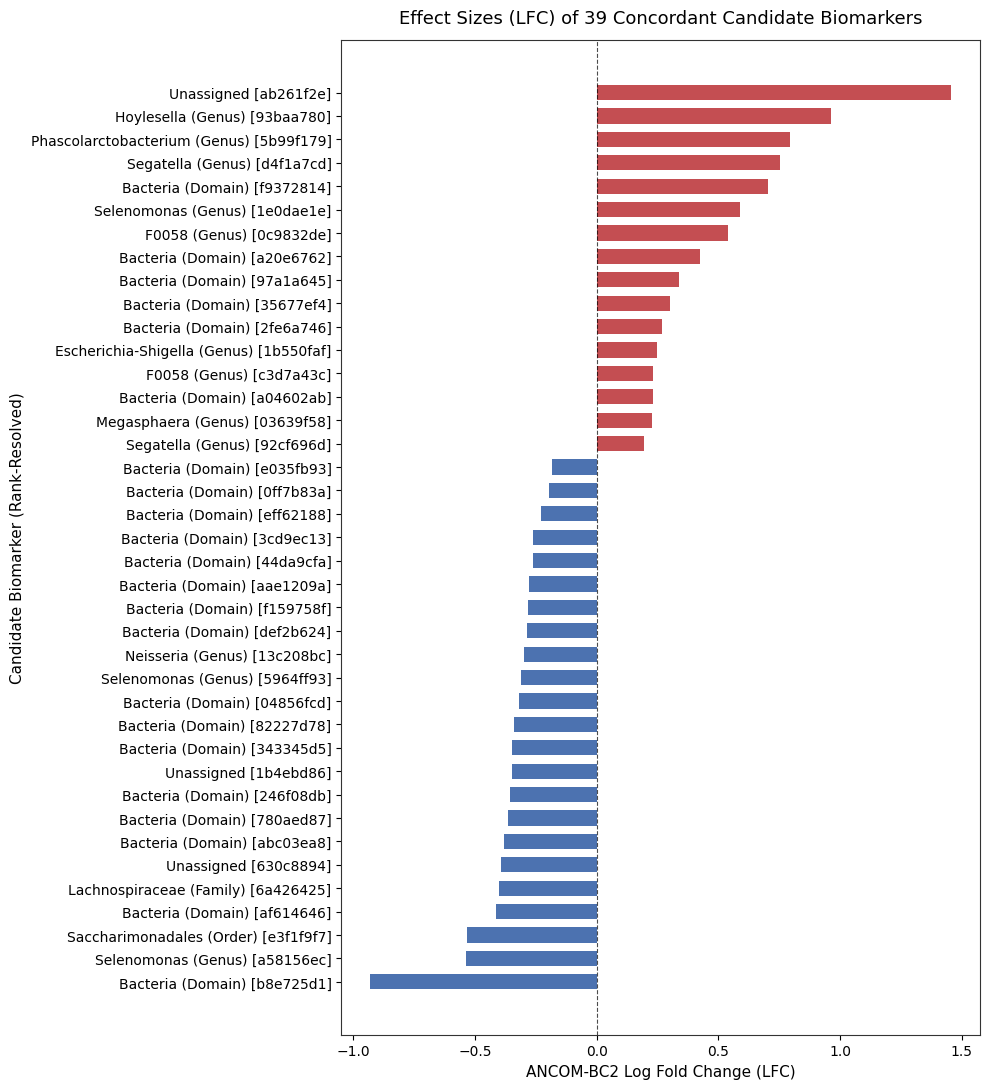

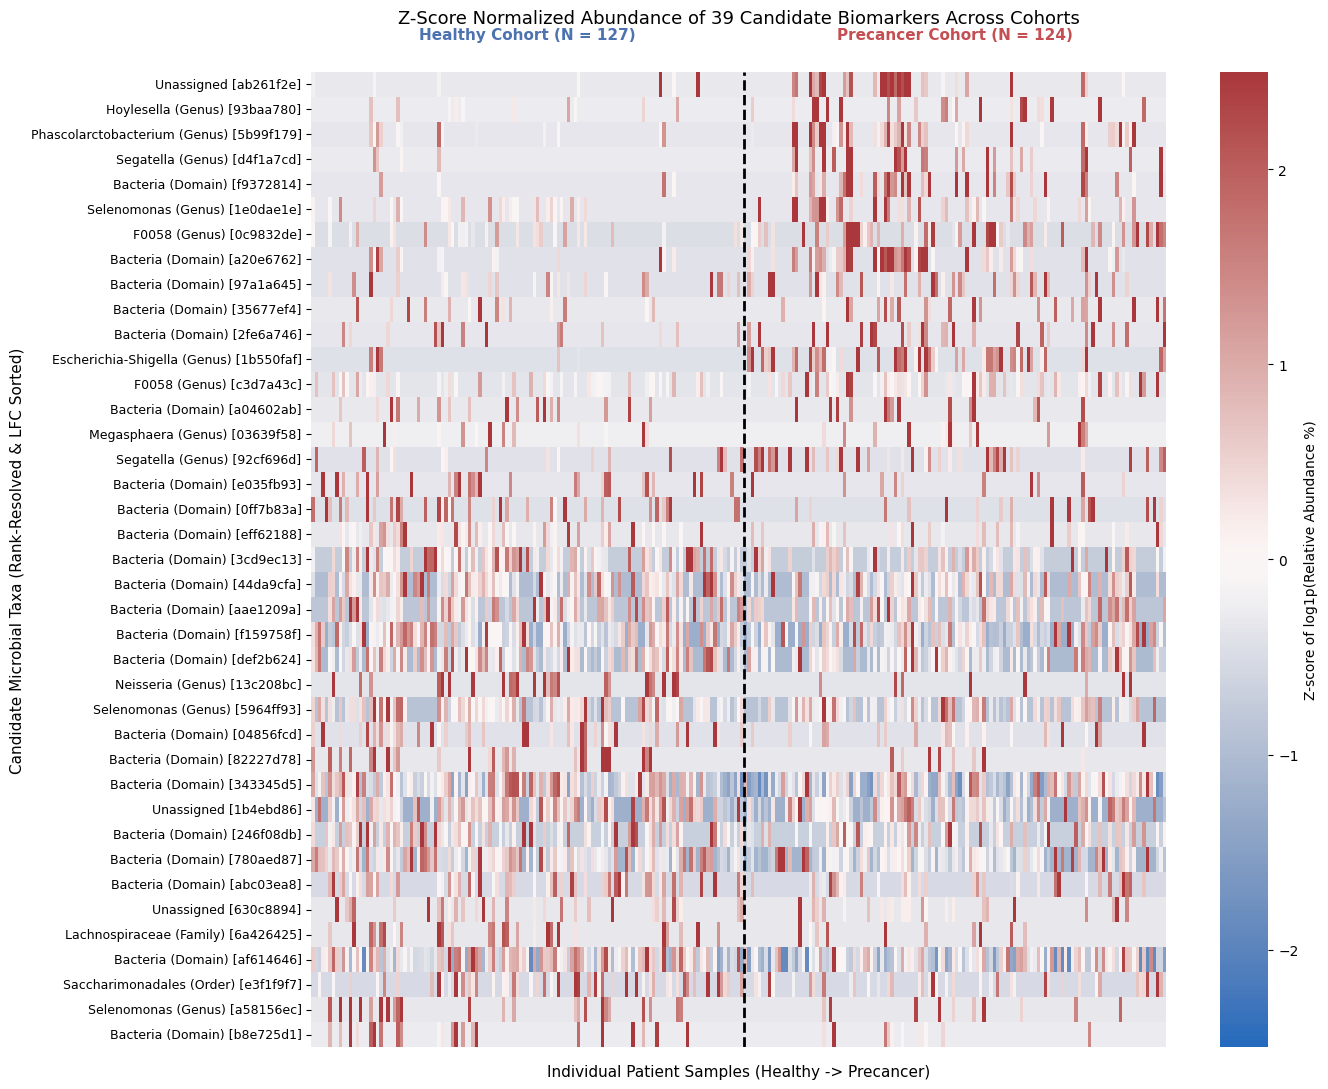

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Top 20 Elastic-Net Predictive Features Bar Plot
top20_coef = nonzero_features.head(20).copy()
tax_lookup = tax['Taxon'].to_dict()
top20_coef['Taxon_Str'] = top20_coef['ASV_ID'].map(tax_lookup)
parsed_top = top20_coef['Taxon_Str'].apply(parse_best_taxonomy)
top20_coef['Display_Label'] = [f"{p[1]} [{a[:8]}]" for p, a in zip(parsed_top, top20_coef['ASV_ID'])]

top20_sorted = top20_coef.sort_values('coefficient', ascending=True)
coef_colors = np.where(top20_sorted['coefficient'] > 0, '#C44E52', '#4C72B0')

plt.figure(figsize=(9.5, 7.5))
plt.barh(top20_sorted['Display_Label'], top20_sorted['coefficient'], color=coef_colors, height=0.65)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.xlabel("Elastic-Net Standardized Coefficient", fontsize=11)
plt.ylabel("Microbial Feature (ASV)", fontsize=11)
plt.title("Top 20 Predictive Features in Elastic-Net Model", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

# 2. ANCOM-BC2 Effect Size (LFC) Bar Plot
candidates_sorted = candidates.sort_values('LFC', ascending=True).copy()
candidates_sorted['Display_Label'] = candidates_sorted['Best_Taxon_Label'] + " [" + candidates_sorted['ASV_ID'].str[:8] + "]"
lfc_colors = np.where(candidates_sorted['LFC'] > 0, '#C44E52', '#4C72B0')

plt.figure(figsize=(10, 11))
plt.barh(candidates_sorted['Display_Label'], candidates_sorted['LFC'], color=lfc_colors, height=0.65)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.xlabel("ANCOM-BC2 Log Fold Change (LFC)", fontsize=11)
plt.ylabel("Candidate Biomarker (Rank-Resolved)", fontsize=11)
plt.title("Effect Sizes (LFC) of 39 Concordant Candidate Biomarkers", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

# 3. Z-Scored LFC-Sorted Clustered Heatmap with Dynamic Clipping [-2.5, +2.5]
relative_abundance = asv_abundance.div(asv_abundance.sum(axis=1), axis=0) * 100
heatmap_df = relative_abundance[candidate_asvs].copy()
heatmap_df["disease_status"] = md.loc[heatmap_df.index, "disease-status"]

ordered_sample_idx = (
    heatmap_df["disease_status"]
    .map({"Healthy": 0, "Precancer": 1})
    .sort_values()
    .index
)
heatmap_df = heatmap_df.loc[ordered_sample_idx]
sample_cohorts = heatmap_df["disease_status"]
heatmap_df = heatmap_df.drop(columns="disease_status")

label_dict = candidates.set_index('ASV_ID')['Best_Taxon_Label'].to_dict()
heatmap_df.columns = [f"{label_dict.get(col, col)} [{col[:8]}]" for col in heatmap_df.columns]

# Log-transform and Z-score normalize across samples
heatmap_log = np.log1p(heatmap_df).T
heatmap_zscore = heatmap_log.sub(heatmap_log.mean(axis=1), axis=0).div(heatmap_log.std(axis=1), axis=0)

# Sort rows by ANCOM-BC2 LFC (enriched at top, depleted at bottom)
lfc_order_labels = candidates.sort_values('LFC', ascending=False)['ASV_ID'].map(lambda x: f"{label_dict.get(x, x)} [{x[:8]}]").tolist()
heatmap_zscore = heatmap_zscore.reindex(lfc_order_labels)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    heatmap_zscore,
    cmap="vlag",
    center=0,
    vmin=-2.5,
    vmax=2.5,
    xticklabels=False,
    yticklabels=True,
    linewidths=0,
    cbar_kws={"label": "Z-score of log1p(Relative Abundance %)"},
    ax=ax
)

plt.yticks(fontsize=9)

n_healthy_samples = (sample_cohorts == "Healthy").sum()
ax.axvline(n_healthy_samples, color="black", linewidth=2, linestyle="--")

ax.text(n_healthy_samples / 2, -1.5, f"Healthy Cohort (N = {n_healthy_samples})",
        ha="center", va="center", fontsize=11, fontweight="bold", color="#4C72B0")
ax.text(n_healthy_samples + (len(sample_cohorts) - n_healthy_samples) / 2, -1.5,
        f"Precancer Cohort (N = {len(sample_cohorts) - n_healthy_samples})",
        ha="center", va="center", fontsize=11, fontweight="bold", color="#C44E52")

ax.set_xlabel("Individual Patient Samples (Healthy -> Precancer)", fontsize=11, labelpad=12)
ax.set_ylabel("Candidate Microbial Taxa (Rank-Resolved & LFC Sorted)", fontsize=11)
ax.set_title("Z-Score Normalized Abundance of 39 Candidate Biomarkers Across Cohorts", fontsize=13, pad=35)

plt.tight_layout()
plt.show()